# Pipeline GPU n°1 : PyTorch → ONNX → TensorRT → CUDA/cuDNN
TP1 Déploiement IA — ResNet-18 / CIFAR-10. **Environnement d'exécution Colab : GPU T4 (Exécution > Modifier le type d'exécution > T4 GPU).**

| Niveau | Composant |
|---|---|
| Haut niveau | PyTorch (ResNet-18 pré-entraîné) |
| Format | ONNX (opset 17) |
| Middle level | TensorRT : fusion de couches, choix des tactiques (kernels), FP32 / FP16 |
| Bas niveau | CUDA, cuDNN, cuBLAS et kernels propres à TensorRT |
| Matériel | GPU Google Colab (T4) |

[Ouvrir dans Colab](https://colab.research.google.com/github/Romain-LM-Dev/TP1_deploiement_IA/blob/main/notebooks/03_gpu_tensorrt.ipynb)

## Protocole (identique aux 4 pipelines, défini dans `common.py`)
- **Données** : les 50 premières images du jeu de test CIFAR-10, redimensionnées de 32×32 à 224×224 (bilinéaire) puis normalisées avec la moyenne/écart-type ImageNet.
- **Modèle** : ResNet-18 pré-entraîné ImageNet (`IMAGENET1K_V1`). Les 1000 classes sont regroupées en 10 classes CIFAR (ex. les 118 races de chiens → *dog*) ; la classe prédite est celle dont le meilleur logit est le plus élevé.
- **Mesure** : batchs de 10 images, données déjà sur le périphérique, 1 appel initial (compilation éventuelle, chronométré à part), 3 passes de chauffe, puis 10 exécutions mesurées des 50 images. Synchronisation explicite après chaque batch sur GPU.
- **Énergie** : compteur matériel (NVML sur GPU, RAPL sur CPU si accessible), intégré sur ≥ 3 s d'inférence en boucle après chaque exécution.
- **Référence** : PyTorch *eager* sur le même matériel, pour mesurer le gain et vérifier que les prédictions ne sont pas dégradées.

In [8]:
!pip install -q tensorrt onnx nvidia-ml-py
!nvidia-smi

Tue Nov  3 16:05:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P0             28W /   70W |     463MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [9]:
# Récupération du dépôt : code commun (données, modèle, protocole de mesure)
import os, subprocess, sys
REPO = "https://github.com/Romain-LM-Dev/TP1_deploiement_IA.git"
if os.path.exists("../common.py"):          # exécution locale depuis notebooks/
    os.chdir("..")
elif not os.path.exists("common.py"):       # Google Colab
    if not os.path.exists("TP1_deploiement_IA"):
        subprocess.run(["git", "clone", "-q", REPO], check=True)
    os.chdir("TP1_deploiement_IA")
sys.path.insert(0, os.getcwd())
import common as C
C.env_info()

{'python': '3.13.16',
 'torch': '2.11.0+cu130',
 'torchvision': '0.26.0+cu130',
 'cpu': 'Intel(R) Xeon(R) CPU @ 2.00GHz',
 'cpu_threads': 1,
 'os_cpu_count': 2,
 'gpu': 'Tesla T4',
 'cuda': '13.0',
 'cudnn': 92700}

In [10]:
import time
from collections import Counter
import numpy as np, torch
from IPython.display import display

torch.manual_seed(C.SEED)
x, y = C.load_data()            # (50, 3, 224, 224), normalisation ImageNet
model = C.load_model()          # ResNet-18 IMAGENET1K_V1, mode eval
print("Entrée :", tuple(x.shape), "| batch :", C.BATCH_SIZE, "| répétitions :", C.N_RUNS)
print("Répartition des classes :", dict(zip(C.CIFAR_CLASSES, np.bincount(y, minlength=10).tolist())))
results = []

Entrée : (50, 3, 224, 224) | batch : 10 | répétitions : 10
Répartition des classes : {'airplane': 5, 'automobile': 3, 'bird': 2, 'cat': 3, 'deer': 5, 'dog': 7, 'frog': 9, 'horse': 4, 'ship': 4, 'truck': 8}


In [11]:
assert torch.cuda.is_available(), "Activer un GPU : Exécution > Modifier le type d'exécution"
torch.backends.cudnn.benchmark = True
meter = C.EnergyMeter("cuda")
print("Source énergie :", meter.source)
onnx_path = C.export_onnx(model)        # export depuis le modèle CPU, avant le passage sur GPU
model = model.cuda()
batches = C.make_batches(x.cuda())     # données déjà sur le GPU : on mesure l'inférence seule
sync = torch.cuda.synchronize

Source énergie : NVML (GPU seul)


## 1. Référence : PyTorch eager sur GPU

In [12]:
with torch.inference_mode():
    eager = C.benchmark("GPU-1 TensorRT", "PyTorch eager (réf.)", model, batches, y, device="cuda",
                        ref=None, sync=sync, meter=meter)
ref = eager["_logits"]
results.append(eager)

PyTorch eager (réf.)            802.8 ±   33.3 img/s |     62.4 ±    2.8 ms / 50 img | acc 64%


## 2. Construction des moteurs TensorRT (middle level)
TensorRT importe le graphe ONNX, fusionne les couches (Conv+BN+ReLU+Add en un seul kernel), puis chronomètre plusieurs implémentations (« tactiques ») de chaque couche sur le GPU pour garder la plus rapide. On construit un moteur FP32 (comparaison équitable) et un moteur FP16 (Tensor Cores du T4).

Le réseau est déclaré *strongly typed* : la précision de chaque couche est celle du graphe ONNX (TensorRT 11 a supprimé le drapeau `BuilderFlag.FP16`). Pour le FP16, on exporte donc un second ONNX dont les poids et les calculs sont en FP16, avec des entrées/sorties FP32 pour garder le même code d'exécution.

In [13]:
import json, onnx, tensorrt as trt
print("TensorRT", trt.__version__)
LOGGER = trt.Logger(trt.Logger.WARNING)
import copy

class FP16Model(torch.nn.Module):
    """Calcul FP16, entrées/sorties FP32 (casts aux extrémités du graphe ONNX)."""
    def __init__(self, m):
        super().__init__()
        self.m = copy.deepcopy(m).half()
    def forward(self, x):
        return self.m(x.half()).float()

onnx_fp16_path = "resnet18_fp16.onnx"
torch.onnx.export(FP16Model(model).eval(), batches[0], onnx_fp16_path, input_names=["input"],
                  output_names=["logits"], opset_version=17, dynamo=False)

FLAGS = trt.NetworkDefinitionCreationFlag
STRONGLY_TYPED = 1 << int(FLAGS.STRONGLY_TYPED) if hasattr(FLAGS, "STRONGLY_TYPED") else 0  # TRT 11 : toujours typé

def build_engine(fp16):
    path = onnx_fp16_path if fp16 else onnx_path
    n_onnx = len(onnx.load(path).graph.node)
    builder = trt.Builder(LOGGER)
    network = builder.create_network(STRONGLY_TYPED)
    parser = trt.OnnxParser(network, LOGGER)
    with open(path, "rb") as f:
        if not parser.parse(f.read()):
            raise RuntimeError([str(parser.get_error(i)) for i in range(parser.num_errors)])
    config = builder.create_builder_config()
    config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 1 << 30)
    config.profiling_verbosity = trt.ProfilingVerbosity.DETAILED
    t0 = time.perf_counter()
    plan = builder.build_serialized_network(network, config)
    build_s = time.perf_counter() - t0
    engine = trt.Runtime(LOGGER).deserialize_cuda_engine(plan)
    info = json.loads(engine.create_engine_inspector().get_engine_information(trt.LayerInformationFormat.JSON))
    layers = [l for l in info["Layers"] if isinstance(l, dict)]
    print(f"{'FP16' if fp16 else 'FP32'} : construit en {build_s:.1f} s | {n_onnx} nœuds ONNX -> "
          f"{network.num_layers} couches TensorRT -> {engine.num_layers} couches dans le moteur")
    for l in layers[:4]:
        print("   ", l.get("Name", "")[:90], "|", l.get("TacticName", ""))
    return engine, build_s

class TRTRunner:
    """Exécute le moteur sur le flux CUDA de PyTorch, sans copie : les tenseurs torch servent de buffers."""
    def __init__(self, engine):
        self.ctx = engine.create_execution_context()
    def __call__(self, b):
        out = torch.empty((b.shape[0], 1000), device="cuda")
        self.ctx.set_tensor_address("input", b.data_ptr())
        self.ctx.set_tensor_address("logits", out.data_ptr())
        self.ctx.execute_async_v3(torch.cuda.current_stream().cuda_stream)
        return out

TensorRT 11.4.0.106


/tmp/ipykernel_1445/549097605.py:15: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(FP16Model(model).eval(), batches[0], onnx_fp16_path, input_names=["input"],


## 3. Mesures TensorRT FP32 et FP16

In [14]:
for fp16 in (False, True):
    engine, build_s = build_engine(fp16)
    r = C.benchmark("GPU-1 TensorRT", f"TensorRT {'FP16' if fp16 else 'FP32'}", TRTRunner(engine), batches, y,
                    device="cuda", ref=ref, sync=sync, meter=meter)
    r["compile_s"] = build_s
    results.append(r)

FP32 : construit en 6.4 s | 49 nœuds ONNX -> 53 couches TensorRT -> 25 couches dans le moteur
    /conv1/Conv + /relu/Relu | volta_scudnn_128x64_relu_xregs_large_nn_v1
    /maxpool/MaxPool | sm50_xmma_pooling_nd_NCDHW_kMAX_kGENERIC_3D_POOLING_MODE_kFLOAT_0
    /layer1/layer1.0/conv1/Conv + /layer1/layer1.0/relu/Relu | volta_scudnn_winograd_128x128_ldg1_ldg4_relu_tile148t_nt_v1
    /layer1/layer1.0/conv2/Conv + /layer1/layer1.0/Add + /layer1/layer1.0/relu_1/Relu | volta_scudnn_winograd_128x128_ldg1_ldg4_relu_tile148t_nt_v1
TensorRT FP32                  1212.3 ±   30.5 img/s |     41.3 ±    1.0 ms / 50 img | acc 64% | accord eager 100%, max|Δlogit| 3.43e-05
FP16 : construit en 19.2 s | 51 nœuds ONNX -> 55 couches TensorRT -> 26 couches dans le moteur
    /Cast | 
    /m/conv1/Conv + /m/relu/Relu | sm75_xmma_fprop_image_first_layer_f16f16_f32_f16_nhwckrsc_nhwc_hmma_k64c4r7s7_stride2x2_tile16x64x64_tensor1688
    /m/maxpool/MaxPool | sm50_xmma_pooling_max_nhwc_FP16FP32_WINDOWSIZE_3_NOT_PR

## 4. Synthèse, graphiques et sauvegarde

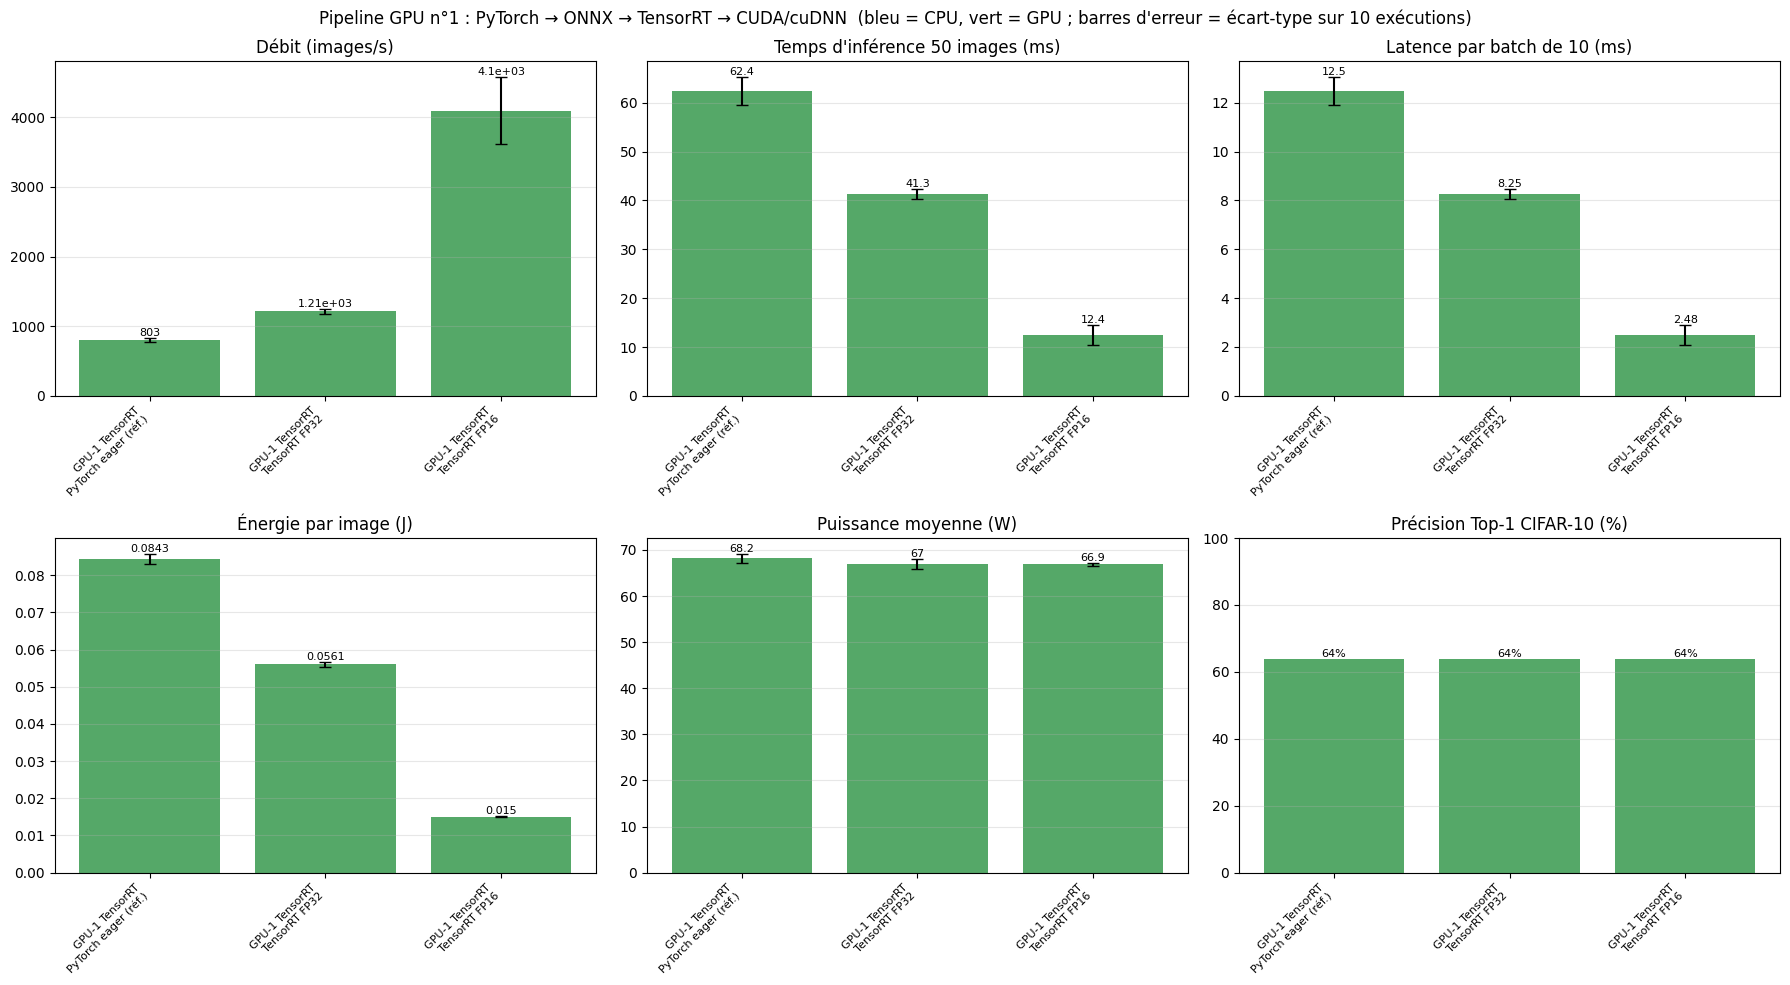

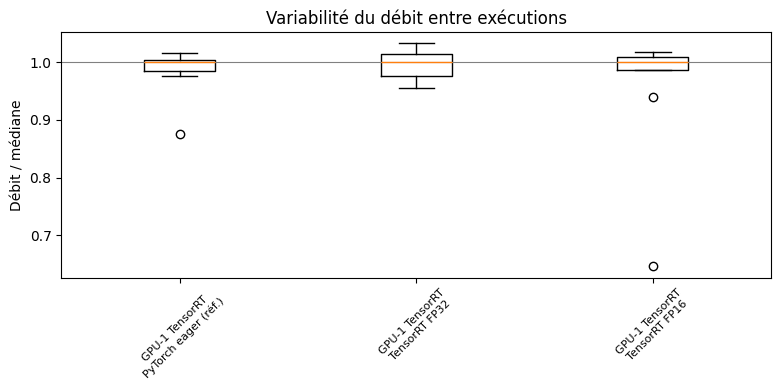

,0,1,2
pipeline,GPU-1 TensorRT,GPU-1 TensorRT,GPU-1 TensorRT
variant,PyTorch eager (réf.),TensorRT FP32,TensorRT FP16
throughput_mean,802.7605,1212.2818,4095.4353
throughput_std,33.2969,30.5221,480.4942
throughput_min,712.3689,1163.2287,2755.3504
throughput_max,826.7281,1256.5255,4340.6881
throughput_cv_pct,4.1478,2.5177,11.7324
total_ms_mean,62.3912,41.2682,12.4226
total_ms_std,2.8434,1.0447,2.0299
total_ms_min,60.4794,39.7923,11.5189


Résultats écrits dans results/03_gpu_tensorrt.json


[résultats 03_gpu_tensorrt intégrés au notebook]

In [15]:
df = C.plot_summary(results, "Pipeline GPU n°1 : PyTorch → ONNX → TensorRT → CUDA/cuDNN", "figures/03_gpu_tensorrt.png")
display(df[C.TABLE_COLS].round(4).T)
path = C.save_results("03_gpu_tensorrt", results, {"tensorrt": trt.__version__})

In [16]:
# Colab dans le navigateur : télécharge le JSON (à déposer dans results/ du dépôt).
# Extension Colab de VS Code : rien à faire, il suffit d'enregistrer le notebook (résultats intégrés ci-dessus).
try:
    from google.colab import files
    files.download(path)
except Exception:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Lecture des résultats
- **Débit / temps** : comparer chaque variante à la référence *eager* de ce notebook (même machine, même session).
- **Stabilité** : un coefficient de variation (`throughput_cv_pct`) < 5 % indique des mesures reproductibles ; au-delà, regarder le *boxplot* (valeurs aberrantes = interférences de la VM partagée).
- **Qualité** : `agreement_vs_eager` doit valoir 100 % et `max_abs_diff_vs_eager` rester faible (~1e-4 en FP32).
- L'analyse croisée des 4 pipelines est faite dans `05_comparaison.ipynb` et dans le rapport.